# Tratamento e pré-processamento dos dados

As respostas coletadas no formulário precisam ser convertidas para um formato adequado para a análise.

1) As colunas precisam ser renomeadas para representar os nomes das variáveis, não perguntas.

2) Os dados númericos contínuos foram discretizados em faixas. Será preciso analisar a possibilidade de converter esses dados para novas colunas com valores contínuos.

3) Variáveis númericas podem ter resíduos de strings, e portanto devem ser limpadas.

In [49]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
DATA_DIR = ROOT_DIR / "data"
OUTPUT_DIR = ROOT_DIR / "output"

if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))
print("Root: ", ROOT_DIR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Don't truncate columns when showing the table
pd.set_option('display.max_columns', None)

df_raw = pd.read_csv(DATA_DIR / "raw_data.csv")
print("Dataframe successfully loaded.")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Root:  c:\Users\Pedro\projetos\poli\trabalho_estat
Dataframe successfully loaded.


In [50]:
df_raw.columns

Index(['Carimbo de data/hora',
       'Ao prosseguir, você confirma que é aluno(a) de graduação da Escola Politécnica da USP, compreende os objetivos desta pesquisa e concorda em compartilhar suas respostas para fins exclusivamente acadêmicos?',
       '1. Qual é o seu curso atual na Escola Politécnica da USP?',
       '2. Qual o seu ano de ingresso na Faculdade?',
       '3. Em qual tipo de escola você cursou o ensino médio?',
       '4. Qual o tempo médio de deslocamento (apenas ida) da sua residência até a Poli, aproximadamente?',
       '5. Além das atividades acadêmicas e do grupo de extensão, você exerce alguma atividade remunerada externa à faculdade (ex: trabalho formal, trabalho autônomo, empresa própria, etc.)?',
       '6. Qual a renda familiar total do seu domicílio?',
       '7. Qual a sua média ponderada acumulada atual, aproximadamente?',
       '8. Atualmente, em qual área você pretende atuar logo após se formar? ',
       '9. Qual é o seu principal grupo de extensão na

## Renomeando colunas

Vamos iniciar pela renomeação das colunas.

In [51]:
cols_names = [
    "timestamp",
    "termo_consentimento",
    "curso",
    "ano_ingresso",
    "tipo_escola",
    "tempo_deslocamento",
    "faz_atividade_remunerada",
    "renda_familiar",
    "media_ponderada",
    "area_pretendida",
    "grupo_extensao",
    "motivacao_ingresso",
    "tempo_grupo",
    "horas_semanais_grupo",
    "outras_extracurriculares",
    "objetivo_faculdade",
    "momento_estagio",
    "importancia_media",
    "preparo_disciplinas",
    "preparo_extensao",
]

df_renamed = df_raw.copy()
df_renamed.columns = cols_names
df_renamed.columns

Index(['timestamp', 'termo_consentimento', 'curso', 'ano_ingresso',
       'tipo_escola', 'tempo_deslocamento', 'faz_atividade_remunerada',
       'renda_familiar', 'media_ponderada', 'area_pretendida',
       'grupo_extensao', 'motivacao_ingresso', 'tempo_grupo',
       'horas_semanais_grupo', 'outras_extracurriculares',
       'objetivo_faculdade', 'momento_estagio', 'importancia_media',
       'preparo_disciplinas', 'preparo_extensao'],
      dtype='str')

## Tratamento dos dados

Prosseguimos para o tratamento dos dados em questão. Primeiramente, vamos fazer a conversão das variáveis para o formato adequado (categóricas ou flags boleanas) e definir uma ordem lógica entre as categorias quando necessário. Droparemos também a coluna de timestamp (uma coluna apenas de auditoria).

In [52]:
df_renamed.head()

,timestamp,termo_consentimento,curso,ano_ingresso,tipo_escola,tempo_deslocamento,faz_atividade_remunerada,renda_familiar,media_ponderada,area_pretendida,grupo_extensao,motivacao_ingresso,tempo_grupo,horas_semanais_grupo,outras_extracurriculares,objetivo_faculdade,momento_estagio,importancia_media,preparo_disciplinas,preparo_extensao
0,25/10/2026 18:34:46,"Sim, li e concordo em participar",Engenharia Civil,2026,Privada,30 a 60 min,"Sim, em regime parcial/eventual (aulas particu...",Acima de 20 salários mínimos,7.0 a 7.9,Empreendedorismo,Poli Júnior,Adquirir experiência prática em projetos reais,6 meses a 1 ano,21 a 40h,Nenhuma outra atividade extracurricular,Foco no grupo de extensão,No 3ºano,2,1,5
1,25/10/2026 18:36:31,"Sim, li e concordo em participar",Engenharia Elétrica,2026,Privada,Menos de 30 min,Não exerço nenhuma atividade remunerada externa,Acima de 20 salários mínimos,8.0 a 8.9,Mercado Financeiro,Poli Júnior,Adquirir experiência prática em projetos reais,6 meses a 1 ano,21 a 40h,Nenhuma outra atividade extracurricular,Foco no grupo de extensão,No 4ºano,1,1,5
2,25/10/2026 18:38:38,"Sim, li e concordo em participar",Engenharia Elétrica,2025,Privada,30 a 60 min,Não exerço nenhuma atividade remunerada externa,De 10 a 20 salários mínimos,6.0 a 6.9,Empreendedorismo,Poli Júnior,Interesse pela temática e objetivos do grupo,1 a 2 anos,Mais de 40h,Nenhuma outra atividade extracurricular,Foco no grupo de extensão,No 4ºano,3,3,4
3,25/10/2026 18:42:44,"Sim, li e concordo em participar",Engenharia Elétrica,2025,Privada,60 a 120 min,Não exerço nenhuma atividade remunerada externa,Acima de 20 salários mínimos,8.0 a 8.9,Indefinido,Poli Júnior,"Desenvolvimento pessoal, comunicação e lideran...",1 a 2 anos,Mais de 40h,Nenhuma outra atividade extracurricular,Foco no grupo de extensão,No 4ºano,2,1,5
4,25/10/2026 18:54:48,"Sim, li e concordo em participar",Engenharia de Materiais/Metalúrgica/Nuclear,2025,Privada,30 a 60 min,Não exerço nenhuma atividade remunerada externa,Prefiro não informar,7.0 a 7.9,Consultoria,Poli Júnior,Interesse pela temática e objetivos do grupo,6 meses a 1 ano,11 a 20h,Nenhuma outra atividade extracurricular,Foco no grupo de extensão,No 4ºano,3,2,4


A variável "outras_extracurriculares" permite múltipla escolha, e deve ser explodida para várias flags para possibilitar a análise.

In [53]:
df_renamed["outras_extracurriculares"].value_counts()

outras_extracurriculares
Nenhuma outra atividade extracurricular                    130
Esportes                                                    43
Outros grupos de extensão (além do principal)               13
Gestão de CAs ou Grêmios                                     4
Esportes, Outros grupos de extensão (além do principal)      3
Name: count, dtype: int64

In [54]:
from src.preprocessing import convert_responses

df_clean = convert_responses(df_renamed, exclude_non_poli=True)
df_clean.head()

,curso,ano_ingresso,tipo_escola,tempo_deslocamento,faz_atividade_remunerada,renda_familiar,media_ponderada,area_pretendida,grupo_extensao,motivacao_ingresso,tempo_grupo,horas_semanais_grupo,objetivo_faculdade,momento_estagio,importancia_media,preparo_disciplinas,preparo_extensao,extra_esportes,extra_outro_grupo,extra_ca_gremio
0,Engenharia Civil,2026,Privada,30 a 60 min,"Sim, em regime parcial/eventual (aulas particu...",Acima de 20 salários mínimos,7.0 a 7.9,Empreendedorismo,Poli Júnior,Adquirir experiência prática em projetos reais,6 meses a 1 ano,21 a 40h,Foco no grupo de extensão,No 3ºano,2,1,5,False,False,False
1,Engenharia Elétrica,2026,Privada,Menos de 30 min,Não exerço nenhuma atividade remunerada externa,Acima de 20 salários mínimos,8.0 a 8.9,Mercado Financeiro,Poli Júnior,Adquirir experiência prática em projetos reais,6 meses a 1 ano,21 a 40h,Foco no grupo de extensão,No 4ºano,1,1,5,False,False,False
2,Engenharia Elétrica,2025,Privada,30 a 60 min,Não exerço nenhuma atividade remunerada externa,De 10 a 20 salários mínimos,6.0 a 6.9,Empreendedorismo,Poli Júnior,Interesse pela temática e objetivos do grupo,1 a 2 anos,Mais de 40h,Foco no grupo de extensão,No 4ºano,3,3,4,False,False,False
3,Engenharia Elétrica,2025,Privada,60 a 120 min,Não exerço nenhuma atividade remunerada externa,Acima de 20 salários mínimos,8.0 a 8.9,Indefinido,Poli Júnior,"Desenvolvimento pessoal, comunicação e lideran...",1 a 2 anos,Mais de 40h,Foco no grupo de extensão,No 4ºano,2,1,5,False,False,False
4,Engenharia de Materiais/Metalúrgica/Nuclear,2025,Privada,30 a 60 min,Não exerço nenhuma atividade remunerada externa,NaN,7.0 a 7.9,Consultoria,Poli Júnior,Interesse pela temática e objetivos do grupo,6 meses a 1 ano,11 a 20h,Foco no grupo de extensão,No 4ºano,3,2,4,False,False,False


Algumas perguntas do fomulário apresentavam a possibilidade de responder "outro: ___". É preciso analisar essas respostas não padronizadas e 1) converter para um formato conveniente, 2) agregar para uma categoria já existente ou 3) dropar.

In [55]:
for col in df_renamed.columns:
    print(f"{col} --- {df_renamed[col].value_counts().shape}")

timestamp --- (193,)
termo_consentimento --- (1,)
curso --- (12,)
ano_ingresso --- (5,)
tipo_escola --- (3,)
tempo_deslocamento --- (4,)
faz_atividade_remunerada --- (3,)
renda_familiar --- (5,)
media_ponderada --- (7,)
area_pretendida --- (6,)
grupo_extensao --- (9,)
motivacao_ingresso --- (6,)
tempo_grupo --- (4,)
horas_semanais_grupo --- (5,)
outras_extracurriculares --- (5,)
objetivo_faculdade --- (13,)
momento_estagio --- (5,)
importancia_media --- (5,)
preparo_disciplinas --- (5,)
preparo_extensao --- (3,)


In [56]:
df_clean["objetivo_faculdade"].value_counts()

objetivo_faculdade
Foco no grupo de extensão                                                                                                             77
Busca e realização de estágio                                                                                                         48
Desempenho acadêmico (manter/elevar a média ponderada)                                                                                27
Planejamento e realização de intercâmbio                                                                                              21
Iniciação científica / Pesquisa acadêmica                                                                                              6
Aprender e me desenvolver na área de interesse                                                                                         1
Aprender o máximo possível, seja no grupo de extensão ou não.                                                                          1
Estou atualmente em in

Fica claro que a variável "objetivo_faculdade" tem respostas não padronizadas, embora muitas delas sejam combinações das outras. Vemos que uma resposta pode ser incorporada a uma das categorias padrões. As outras, por serem quantitativamente despreziveis, serão substituídas por NaN. 

- Usar uma técnica de flags boleanas iria contra a metodologia adotada de escolha única, tornando as outras respostas irrealistas e impossibilitando testes de associação.

- Incorporar uma categoria "outros" esconderia a natureza real dessas categorias, que são em sua maioria combinações das opções padrões, além de ter um tamanho na amostra praticamente insignificante (7 observações).

In [57]:
categories_validated = {
    "Foco no grupo de extensão": "Grupo de extensão",
    "Busca e realização de estágio": "Estágio",
    "Desempenho acadêmico (manter/elevar a média ponderada)": "Desempenho acadêmico",
    "Planejamento e realização de intercâmbio": "Intercâmbio",
    "Iniciação científica / Pesquisa acadêmica": "IC / Pesquisa",
    "Estou atualmente em intercâmbio (por isso o baixo tempo no grupo de extensão, também)": "Intercâmbio"
}

df_clean["objetivo_faculdade"] = df_clean["objetivo_faculdade"].map(categories_validated).astype("category")
df_clean["objetivo_faculdade"].value_counts(dropna=False)

objetivo_faculdade
Grupo de extensão       77
Estágio                 48
Desempenho acadêmico    27
Intercâmbio             22
NaN                      7
IC / Pesquisa            6
Name: count, dtype: int64

Vamos converter também as categorias da variável "faz_atividade_remunerada" para um formato mais sucinto.

In [58]:
df_clean["faz_atividade_remunerada"].value_counts()

faz_atividade_remunerada
Não exerço nenhuma atividade remunerada externa                                  159
Sim, em regime parcial/eventual (aulas particulares, serviços pontuais, etc.)     20
Sim, em regime recorrente/contínuo (trabalho CLT, PJ, sócio em empresa, etc.)      8
Name: count, dtype: int64

In [59]:
categories_to_map = {
    "Não exerço nenhuma atividade remunerada externa": "Não",
    "Sim, em regime parcial/eventual (aulas particulares, serviços pontuais, etc.)": "Parcial / pontual",
    "Sim, em regime recorrente/contínuo (trabalho CLT, PJ, sócio em empresa, etc.)": "Recorrente / contínuo"
}

df_clean["faz_atividade_remunerada"] = pd.Categorical(
    df_clean["faz_atividade_remunerada"].str.strip().map(categories_to_map),
    categories=["Não", "Parcial / pontual", "Recorrente / contínuo"],
    ordered=True,
)
df_clean["faz_atividade_remunerada"].value_counts()

faz_atividade_remunerada
Não                      159
Parcial / pontual         20
Recorrente / contínuo      8
Name: count, dtype: int64

Vamos observar o resultado final:

In [60]:
df_clean.head()

,curso,ano_ingresso,tipo_escola,tempo_deslocamento,faz_atividade_remunerada,renda_familiar,media_ponderada,area_pretendida,grupo_extensao,motivacao_ingresso,tempo_grupo,horas_semanais_grupo,objetivo_faculdade,momento_estagio,importancia_media,preparo_disciplinas,preparo_extensao,extra_esportes,extra_outro_grupo,extra_ca_gremio
0,Engenharia Civil,2026,Privada,30 a 60 min,Parcial / pontual,Acima de 20 salários mínimos,7.0 a 7.9,Empreendedorismo,Poli Júnior,Adquirir experiência prática em projetos reais,6 meses a 1 ano,21 a 40h,Grupo de extensão,No 3ºano,2,1,5,False,False,False
1,Engenharia Elétrica,2026,Privada,Menos de 30 min,Não,Acima de 20 salários mínimos,8.0 a 8.9,Mercado Financeiro,Poli Júnior,Adquirir experiência prática em projetos reais,6 meses a 1 ano,21 a 40h,Grupo de extensão,No 4ºano,1,1,5,False,False,False
2,Engenharia Elétrica,2025,Privada,30 a 60 min,Não,De 10 a 20 salários mínimos,6.0 a 6.9,Empreendedorismo,Poli Júnior,Interesse pela temática e objetivos do grupo,1 a 2 anos,Mais de 40h,Grupo de extensão,No 4ºano,3,3,4,False,False,False
3,Engenharia Elétrica,2025,Privada,60 a 120 min,Não,Acima de 20 salários mínimos,8.0 a 8.9,Indefinido,Poli Júnior,"Desenvolvimento pessoal, comunicação e lideran...",1 a 2 anos,Mais de 40h,Grupo de extensão,No 4ºano,2,1,5,False,False,False
4,Engenharia de Materiais/Metalúrgica/Nuclear,2025,Privada,30 a 60 min,Não,NaN,7.0 a 7.9,Consultoria,Poli Júnior,Interesse pela temática e objetivos do grupo,6 meses a 1 ano,11 a 20h,Grupo de extensão,No 4ºano,3,2,4,False,False,False


In [61]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 187 entries, 0 to 186
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   curso                     187 non-null    category
 1   ano_ingresso              187 non-null    int64   
 2   tipo_escola               187 non-null    category
 3   tempo_deslocamento        187 non-null    category
 4   faz_atividade_remunerada  187 non-null    category
 5   renda_familiar            163 non-null    category
 6   media_ponderada           184 non-null    category
 7   area_pretendida           187 non-null    category
 8   grupo_extensao            187 non-null    category
 9   motivacao_ingresso        187 non-null    category
 10  tempo_grupo               187 non-null    category
 11  horas_semanais_grupo      187 non-null    category
 12  objetivo_faculdade        180 non-null    category
 13  momento_estagio           187 non-null    category
 14  impor

In [62]:
print("NaN count: ", df_clean.isna().any(axis=1).sum())
df_clean.loc[df_clean.isna().any(axis=1), df_clean.isna().any(axis=0)]

NaN count:  30


,renda_familiar,media_ponderada,objetivo_faculdade
4,NaN,7.0 a 7.9,Grupo de extensão
13,De 10 a 20 salários mínimos,8.0 a 8.9,NaN
26,NaN,6.0 a 6.9,Estágio
28,De 10 a 20 salários mínimos,7.0 a 7.9,NaN
37,De 3 a 10 salários mínimos,7.0 a 7.9,NaN
39,NaN,8.0 a 8.9,Grupo de extensão
45,NaN,7.0 a 7.9,Estágio
47,NaN,NaN,Grupo de extensão
51,De 10 a 20 salários mínimos,8.0 a 8.9,NaN
53,NaN,6.0 a 6.9,Estágio


Pela inspeção visual, vemos que temos três colunas com valores NaN (devido a opção "prefiro não informar" ou respostas personalizadas). A forma de lidar com esses valores terá que ser decidida de forma específica em cada análise, conforme conveniente.

Vamos avaliar também se é necessário agregar cursos de forma lógica para compensar uma baixa taxa de amostragem de determinada engenharia.

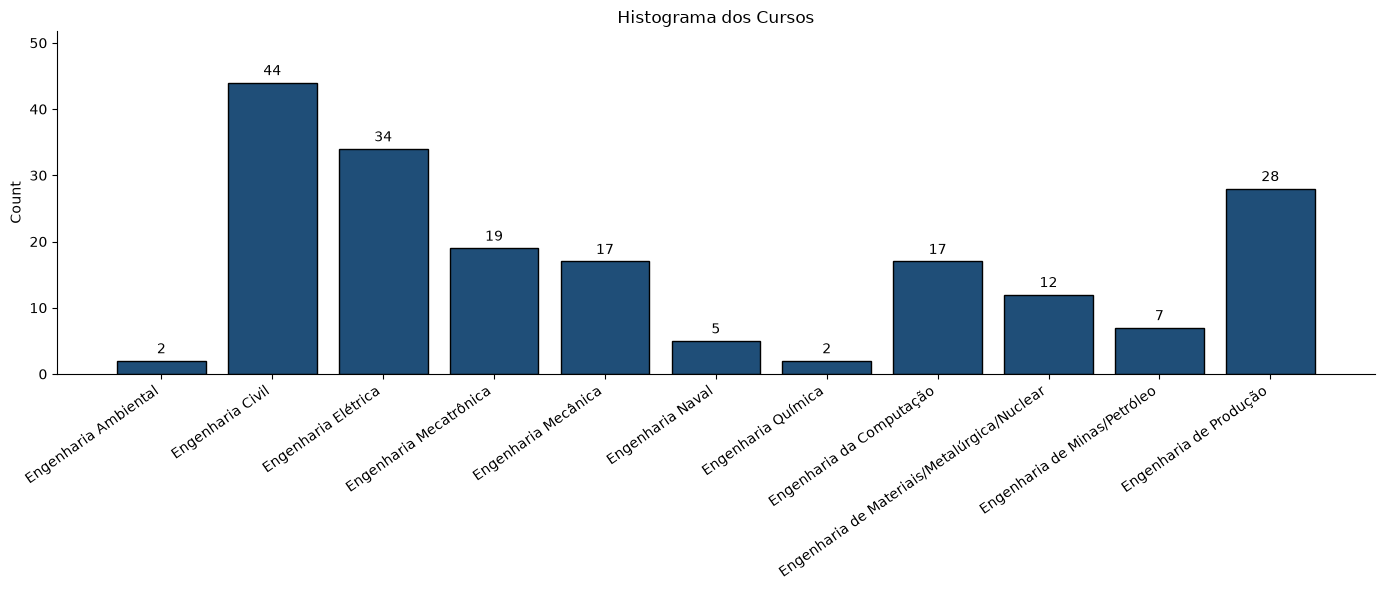

In [63]:
from src.plotting.plots_preprocessing import plot_hist

plot_hist(df_clean, "curso", title="Histograma dos Cursos", figsize=(14, 6))

Os cursos com menor taxa de amostragem foram Eng. Ambiental, Eng. Naval, Eng. Química e Eng. de Minas/Petróleo. Para garantir a significância estatística em testes futuros, vamos agregar as engenharias conforme as grandes áreas:

- **Civil & Ambiental**: Engenharia Civil + Engenharia Ambiental

- **Elétrica & Computação**: Engenharia Elétrica + Engenhari da Computação

- **Mecânica, Mecatrônica e Naval**: Engenharia Mecânica + Engenharia Mecatrônica + Engenharia Naval

- **Produção**: Engenharia de Produção

- **Outras Engenharias**: Por apresentarem baixa amostragem, mas não se relacionarem diretamente, vamos optar por combinar os outros cursos em um único.

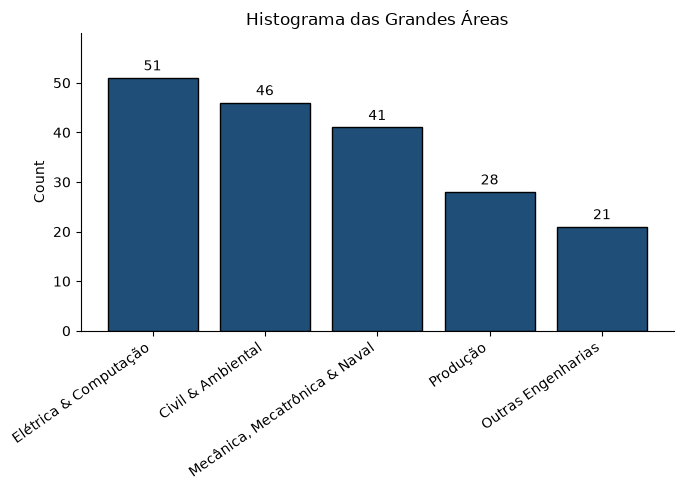

In [64]:
mapa_cursos = {
    "Engenharia Elétrica": "Elétrica & Computação",
    "Engenharia da Computação": "Elétrica & Computação",
    "Engenharia Civil": "Civil & Ambiental",
    "Engenharia Ambiental": "Civil & Ambiental",
    "Engenharia Mecatrônica": "Mecânica, Mecatrônica & Naval",
    "Engenharia Mecânica": "Mecânica, Mecatrônica & Naval",
    "Engenharia Naval": "Mecânica, Mecatrônica & Naval",
    "Engenharia de Produção": "Produção",
}

df_clean["grande_area_curso"] = df_clean["curso"].map(mapa_cursos).fillna("Outras Engenharias")

plot_hist(df_clean, "grande_area_curso", order_freq=True, title="Histograma das Grandes Áreas", figsize=(7, 5))

## Criação de variáveis

Algumas variáveis podem ser criadas antecipadamente devido ao seu carácter mais geral. Algumas possibilidades:

- Categorização dos grupos de extensão.

- Anos de poli (padronização do "ano ideal")

- Quantidade de outras atividades (mensura quanto o aluno divide o seu tempo fora do seu grupo principal)

- Delta preparo (preparação do grupo de extensão vs preperação das disciplinas obrigarórias). Permite transformar a preparação do grupo de extensão para uma escala relativa.

In [65]:
df_clean["grupo_extensao"].value_counts()

grupo_extensao
Poli Júnior                         75
Thunder Ratz                        29
Poli Racing                         16
Grupo de Negócios da Poli           15
Poli Quant                          13
Poli Real State                     12
Poli Consulting Club                10
Poli Finance                         9
Liga de Empreendedorismo da Poli     8
Name: count, dtype: int64

In [66]:
cat_map = {
    # Consultoria & Negócios
    'Poli Júnior': 'Consultoria & Negócios',
    'Grupo de Negócios da Poli': 'Consultoria & Negócios',
    'Poli Consulting Club': 'Consultoria & Negócios',

    # Mercado Financeiro & Dados
    'Poli Quant': 'Mercado Financeiro',
    'Poli Real State': 'Mercado Financeiro',
    'Poli Finance': 'Mercado Financeiro',

    # Engenharia
    'Thunder Ratz': 'Engenharia',
    'Poli Racing': 'Engenharia',
     
    # Empreendedorismo
    'Liga de Empreendedorismo da Poli': 'Empreendedorismo',
}

df_clean["categoria_extensao"] = df_clean["grupo_extensao"].map(cat_map).fillna("Outros")
df_clean["categoria_extensao"].value_counts()

categoria_extensao
Consultoria & Negócios    100
Engenharia                 45
Mercado Financeiro         34
Empreendedorismo            8
Name: count, dtype: int64

In [67]:
df_clean["anos_de_poli"] = 2026 - df_renamed["ano_ingresso"] + 1
df_clean["delta_preparo"] = df_clean["preparo_extensao"] - df_clean["preparo_disciplinas"]

# extra_esportes + extra_ca_gremio + extra_outro_grupo
df_clean["qtd_outras_atividades"] = \
    df_clean["extra_esportes"].astype("int16") + \
    df_clean["extra_ca_gremio"].astype("int16") + \
    df_clean["extra_outro_grupo"].astype("int16")

df_clean[["anos_de_poli", "qtd_outras_atividades"]]

,anos_de_poli,qtd_outras_atividades
0,1,0
1,1,0
2,2,0
3,2,0
4,2,0
...,...,...
182,1,1
183,2,2
184,3,0
185,3,0


## Aproximação contínua dos dados intervalares

Como dito anteriormente, as variáveis contínuas foram aproximadas para variáveis discretas em faixas. Vamos analisar os histogramas desses grupos e tentar ajustar distribuições conhecidas à esses dados, performando testes para analisar a qualidade do ajuste. 

Embora este passo esteja sendo realizado no pré-processamento, devido a primordialidade dessa aproximação para a aplicação de ANOVAs, testes t, ICs e regressões, vale notar que ele tem um fim em si mesmo: podemos inferir a distribuição da população (análise descritiva).

**Metodologia**:

- Ajustar uma distribuição a partir do método dos Estimadores de Máxima Log-Verossimilhança para dados intervalares (*binned MLE*).

- Aplicar um teste de aderência com critério de decisão $\alpha=5%$.


Observe quaisquer testes aplicados em cima dessas aproximações devem ser cuidadosamente analisados e adotar um critério mais rigoroso, devido à incerteza intrínseca associada à essa aproximação. 

Ademais, vamos desconsiderar a variável "tempo_grupo" como contínua pois cada grupo faz o PS em diferentes períodos do ano, com durações diferentes, então não seria realista transformar essa variável. O foco da análise será em "tempo_deslocamento", "media_ponderada" e "horas_semanais_grupo".


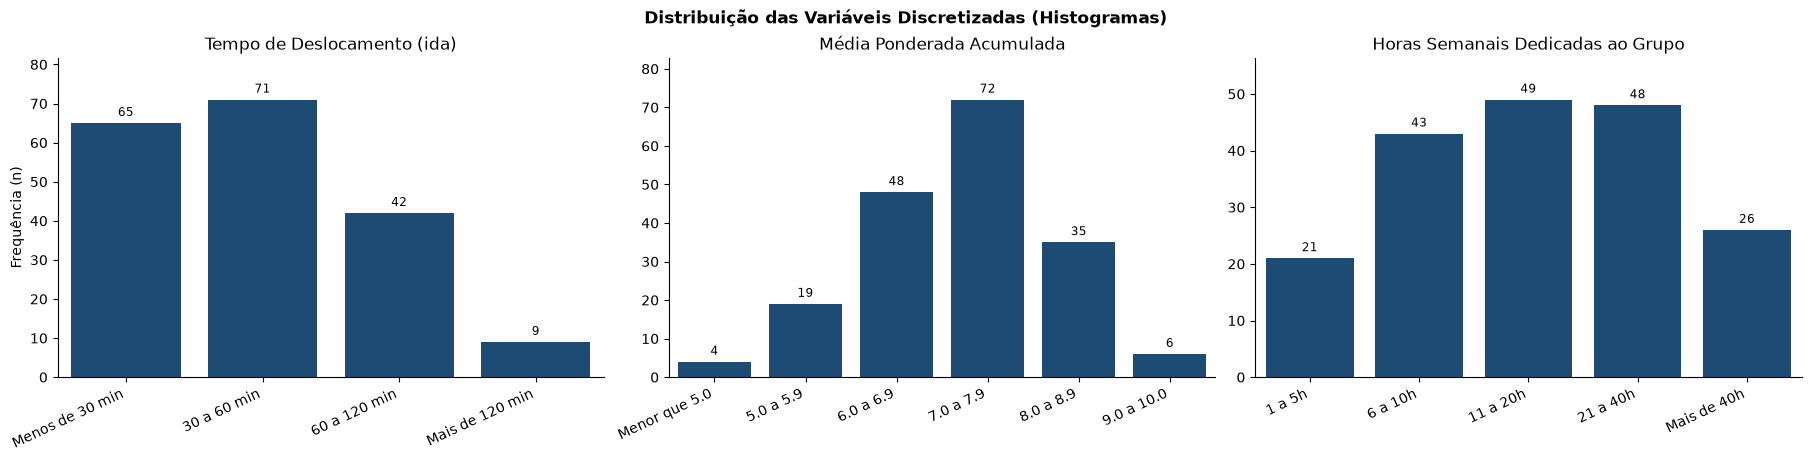

In [68]:
from src.plotting.plots_preprocessing import plot_histograms

TITLES = {
    "tempo_deslocamento": "Tempo de Deslocamento (ida)",
    "media_ponderada": "Média Ponderada Acumulada",
    "horas_semanais_grupo": "Horas Semanais Dedicadas ao Grupo",
}

plot_histograms(df_clean, titles=TITLES)

Por inspeção visual, vemos que as variáveis parecem se ajustar a uma distribuição lognormal (i.e. $\ln{X} \sim \mathcal{N}(\mu, \sigma)$) ou a uma distribuição normal (no caso da "media_ponderada"). Antes de calcular os estimadores, vale uma revisão conceitual.

> **Método: Binned MLE**
>
> A variável aleatória $X$ é dividida em $K$ intervalos disjuntos, $B_1, B_2, ..., B_K$, cada intervalo $j$ definido pelo intervalo $[a_{j-1}, a_j)$. Em vez dos valores $x_i$, observamos apenas as frequências absolutas $n_1, n_2, ..., n_K$ tais que $\sum_{j=1}^K n_j = N$. 
> 
> A probabilidade de uma observação cair no intervalo $j$ dado o  vetor de parâmetros $\theta$ é dada por:
> 
> $$p_j(\theta) = P(X \in B_j | \theta) = \int_{a_{j-1}}^{a_j} f(x | \theta) dx = F(a_j | \theta) - F(a_{j-1} | \theta)$$
> 
> Dado que o número de amostras $N$ é conhecido, o vetor de contagens $(n_1, ..., n_K)$ segue uma distribuição Multinomial - uma distribuição binomial estendida para $K$ categorias:
> 
> $$\mathcal{L}_{\text{mult}}(\theta) = P(N_1 = n_1, ..., N_K = n_K | \theta) = \frac{N!}{n_1! ... n_K!} \prod_{j=1}^K [p_j(\theta)]^{n_j}$$
> 
> Esta é a função de Máxima Verossimilhança. Aplicando o logaritmo natural, e descartando os termos que não dependem de $\theta$ e desapareceriam na derivada, obtemos a função de Máxima Log-Verossimilhança (retomando a definição de $p_j(\theta)$):
> 
> $$\ell_{\text{mult}}(\theta) = \ln{(\mathcal{L}_{\text{mult}}(\theta))} = \sum_{j=1}^K n_j \ln{[F(a_j | \theta) - F(a_{j-1} | \theta)]}$$
>
> Note que ela é, de certa forma, semelhante à função MLE padrão, dada por:
>
> $$\ell(\theta) = \sum_{i=1}^n \ln f(x_i | \theta)$$
>
> Dessa forma, os estimadores de máxima verossimilhança agrupada ($\hat{\boldsymbol{\theta}}$) são definidos como o vetor de parâmetros que maximiza a log-verossimilhança:
>
> $$\hat{\theta} = \argmax_{\theta} \sum_{j=1}^K n_j \ln{[F(a_j | \theta) - F(a_{j-1} | \theta)]}$$

Como não existem funções em python que façam o *binned MLE*, e os estimadores da distribuição Normal e LogNormal não são resolvíveis analiticamente como os obtidos pela MLE padrão, iremos empregar um solver (*scipy.optimize.minimize*). 



In [69]:
from src.plotting.plots_preprocessing import build_gof_summary_df
from src.preprocessing import chi_square_gof, fit_binned_mle

lognorm_cdf = lambda x, mu_ln, sigma_ln: stats.lognorm.cdf(x, s=sigma_ln, scale=np.exp(mu_ln))
norm_cdf = lambda x, mu, sigma: stats.norm.cdf(x, loc=mu, scale=sigma)

alpha = 0.05

# tempo_deslocamento = td
td_order = ["Menos de 30 min", "30 a 60 min", "60 a 120 min", "Mais de 120 min"] 
td_values = df_clean["tempo_deslocamento"].value_counts().reindex(td_order, fill_value=0.0).to_numpy()
td_edges = [0.0, 30.0, 60.0, 120.0, np.inf]
td_params = fit_binned_mle(td_values, td_edges, lognorm_cdf, initial_guess=(np.log(50.0), 0.5))
exp_td, chi2_td, crit_td, dof_td, p_td = chi_square_gof(td_values, td_edges, lognorm_cdf, td_params, alpha)

# media_ponderada = mp
mp_order = ["Menor que 5.0", "5.0 a 5.9", "6.0 a 6.9", "7.0 a 7.9", "8.0 a 8.9", "9.0 a 10.0"]
mp_values = df_clean["media_ponderada"].value_counts().reindex(mp_order, fill_value=0.0).to_numpy()
mp_edges = [-np.inf, 5.0, 6.0, 7.0, 8.0, 9.0, np.inf]  # else we would need to truncate the distribution
mp_params = fit_binned_mle(mp_values, mp_edges, norm_cdf, initial_guess=(7.5, 1.0))
exp_mp, chi2_mp, crit_mp, dof_mp, p_mp = chi_square_gof(mp_values, mp_edges, norm_cdf, mp_params, alpha)

# horas_semanais_grupo = hg
hg_order = ["1 a 5h", "6 a 10h", "11 a 20h", "21 a 40h", "Mais de 40h"]
hg_values = df_clean["horas_semanais_grupo"].value_counts().reindex(hg_order, fill_value=0.0).to_numpy()
hg_edges = [0.0, 5.0, 10.0, 20.0, 40.0, np.inf]  # else we would need to truncate the distribution
hg_params = fit_binned_mle(hg_values, hg_edges, lognorm_cdf, initial_guess=(np.log(15.0), 0.5))
exp_hg, chi2_hg, crit_hg, dof_hg, p_hg = chi_square_gof(hg_values, hg_edges, lognorm_cdf, hg_params, alpha)

# Results table
results = [
    ("Tempo Deslocamento", "Lognormal", td_params, td_values, exp_td, chi2_td, crit_td, dof_td, p_td),
    ("Media Ponderada", "Normal", mp_params, mp_values, exp_mp, chi2_mp, crit_mp, dof_mp, p_mp),
    ("Horas Semanais Grupo", "Lognormal", hg_params, hg_values, exp_hg, chi2_hg, crit_hg, dof_hg, p_hg),
]

df_summary = build_gof_summary_df(results, alpha=0.05)
cols_to_drop_on_save = ["Observed", "Expected", "Diff"]
df_summary.drop(columns=cols_to_drop_on_save).to_csv(OUTPUT_DIR / "tables" / "adhesion_test.csv", index=False)
df_summary

,Variable,Distribution,Param 1 (mu / mu_ln),Param 2 (sigma / sigma_ln),Observed,Expected,Diff,Chi2,Critical,DoF,p-value,Result
0,Tempo Deslocamento,Lognormal,3.6701,0.6822,"[65.0, 71.0, 42.0, 9.0]","[64.84, 72.23, 40.45, 9.49]","[0.16, -1.23, 1.55, -0.49]",0.1058,3.8415,1,0.7450,Fail to reject H0
1,Media Ponderada,Normal,7.2219,1.0254,"[4.0, 19.0, 48.0, 72.0, 35.0, 6.0]","[2.78, 18.69, 54.76, 66.55, 33.59, 7.63]","[1.22, 0.31, -6.76, 5.45, 1.41, -1.63]",2.2267,7.8147,3,0.5267,Fail to reject H0
2,Horas Semanais Grupo,Lognormal,2.7118,0.9146,"[21.0, 43.0, 49.0, 48.0, 26.0]","[21.33, 39.88, 55.09, 44.02, 26.68]","[-0.33, 3.12, -6.09, 3.98, -0.68]",1.2998,5.9915,2,0.5221,Fail to reject H0


In [70]:
from src.plotting.plots_preprocessing import build_gof_summary_df
from src.preprocessing import run_adhesion_tests

alpha = 0.05

var_config = [
    {
        "col": "tempo_deslocamento",
        "label": "Tempo Deslocamento",
        "order": ["Menos de 30 min", "30 a 60 min", "60 a 120 min", "Mais de 120 min"],
        "upper_edges": [30.0, 60.0, 120.0, np.inf],
        "guesses": {"Normal": (50.0, 25.0), "Lognormal": (np.log(50.0), 0.5)},
    },
    {
        "col": "media_ponderada",
        "label": "Media Ponderada",
        "order": ["Menor que 5.0", "5.0 a 5.9", "6.0 a 6.9", "7.0 a 7.9", "8.0 a 8.9", "9.0 a 10.0"],
        "upper_edges": [5.0, 6.0, 7.0, 8.0, 9.0, np.inf],
        "guesses": {"Normal": (7.5, 1.0), "Lognormal": (np.log(7.5), 0.2)},
    },
    {
        "col": "horas_semanais_grupo",
        "label": "Horas Semanais Grupo",
        "order": ["1 a 5h", "6 a 10h", "11 a 20h", "21 a 40h", "Mais de 40h"],
        "upper_edges": [5.0, 10.0, 20.0, 40.0, np.inf],
        "guesses": {"Normal": (15.0, 10.0), "Lognormal": (np.log(15.0), 0.5)},
    },
]


results = run_adhesion_tests(df_clean, var_config, alpha)
df_summary = build_gof_summary_df(results, alpha=alpha)
df_summary

,Variable,Distribution,Param 1 (mu / mu_ln),Param 2 (sigma / sigma_ln),Observed,Expected,Diff,Chi2,Critical,DoF,p-value,Result
0,Tempo Deslocamento,Normal,42.9071,39.6259,"[65.0, 71.0, 42.0, 9.0]","[69.62, 55.09, 57.46, 4.84]","[-4.62, 15.91, -15.46, 4.16]",12.6493,3.8415,1,0.0004,Reject H0
1,Tempo Deslocamento,Lognormal,3.6701,0.6822,"[65.0, 71.0, 42.0, 9.0]","[64.84, 72.23, 40.45, 9.49]","[0.16, -1.23, 1.55, -0.49]",0.1058,3.8415,1,0.7450,Fail to reject H0
2,Media Ponderada,Normal,7.2219,1.0254,"[4.0, 19.0, 48.0, 72.0, 35.0, 6.0]","[2.78, 18.69, 54.76, 66.55, 33.59, 7.63]","[1.22, 0.31, -6.76, 5.45, 1.41, -1.63]",2.2267,7.8147,3,0.5267,Fail to reject H0
3,Media Ponderada,Lognormal,1.9675,0.1469,"[4.0, 19.0, 48.0, 72.0, 35.0, 6.0]","[1.36, 19.94, 59.95, 61.71, 30.19, 10.84]","[2.64, -0.94, -11.95, 10.29, 4.81, -4.84]",12.1864,7.8147,3,0.0068,Reject H0
4,Horas Semanais Grupo,Normal,19.2488,15.7673,"[21.0, 43.0, 49.0, 48.0, 26.0]","[34.24, 17.89, 44.93, 72.36, 17.59]","[-13.24, 25.11, 4.07, -24.36, 8.41]",52.9520,5.9915,2,0.0000,Reject H0
5,Horas Semanais Grupo,Lognormal,2.7118,0.9146,"[21.0, 43.0, 49.0, 48.0, 26.0]","[21.33, 39.88, 55.09, 44.02, 26.68]","[-0.33, 3.12, -6.09, 3.98, -0.68]",1.2998,5.9915,2,0.5221,Fail to reject H0


Os resultados são compatíveis com as expectativas iniciais:

- Não se rejeita a hipótese de aderência à **distribuição lognormal** para o **tempo de deslocamento**;

- Não se rejeita a hipótese de aderência à **distribuição normal** para a **média ponderada**;

- Não se rejeita a hipótese de aderência à **distribuição lognormal** para as **horas de dedicação semanal**;

Vale notar, no entanto, que o primeiro valor esperado da média ponderada é menor que 5. A solução é simples: basta agregar o intervalo $(-\infty; 5.0]$ com o intervalo $(5.0; 6.0]$, resultando em $(-\infty; 6.0]$. Os resultados provavelmente se manterão, pela significância do efeito. Vamos repetir os testes e salvar os resultados.

In [71]:
import copy

var_config_agg = copy.deepcopy(var_config)
var_config_agg[1]["col"] = "media_ponderada_agg"
var_config_agg[1]["order"] = ["Menor que 6.0", "6.0 a 6.9", "7.0 a 7.9", "8.0 a 8.9", "9.0 a 10.0"]
var_config_agg[1]["upper_edges"] = [6.0, 7.0, 8.0, 9.0, np.inf]

# Maps the categories from the df to the new agreggated category
df_temp = df_clean.copy()
df_temp["media_ponderada_agg"] = (
    df_temp["media_ponderada"]
    .astype(str)
    .replace({"Menor que 5.0": "Menor que 6.0", "5.0 a 5.9": "Menor que 6.0"}
)
)

results_agg = run_adhesion_tests(df_temp, var_config_agg, alpha)
df_summary_agg = build_gof_summary_df(results_agg, alpha=alpha)

cols_to_drop_on_save = ["Observed", "Expected", "Diff"]
df_summary_agg.drop(columns=cols_to_drop_on_save).to_csv(OUTPUT_DIR / "tables" / "adhesion_tests.csv", index=False)
print("Results successfully saved.")

df_summary_agg

Results successfully saved.


,Variable,Distribution,Param 1 (mu / mu_ln),Param 2 (sigma / sigma_ln),Observed,Expected,Diff,Chi2,Critical,DoF,p-value,Result
0,Tempo Deslocamento,Normal,42.9071,39.6259,"[65.0, 71.0, 42.0, 9.0]","[69.62, 55.09, 57.46, 4.84]","[-4.62, 15.91, -15.46, 4.16]",12.6493,3.8415,1,0.0004,Reject H0
1,Tempo Deslocamento,Lognormal,3.6701,0.6822,"[65.0, 71.0, 42.0, 9.0]","[64.84, 72.23, 40.45, 9.49]","[0.16, -1.23, 1.55, -0.49]",0.1058,3.8415,1,0.7450,Fail to reject H0
2,Media Ponderada,Normal,7.2302,1.0114,"[23.0, 48.0, 72.0, 35.0, 6.0]","[20.6, 54.84, 67.48, 33.71, 7.37]","[2.4, -6.84, 4.52, 1.29, -1.37]",1.7421,5.9915,2,0.4185,Fail to reject H0
3,Media Ponderada,Lognormal,1.9707,0.1395,"[23.0, 48.0, 72.0, 35.0, 6.0]","[18.37, 60.65, 64.88, 30.48, 9.62]","[4.63, -12.65, 7.12, 4.52, -3.62]",6.6161,5.9915,2,0.0366,Reject H0
4,Horas Semanais Grupo,Normal,19.2488,15.7673,"[21.0, 43.0, 49.0, 48.0, 26.0]","[34.24, 17.89, 44.93, 72.36, 17.59]","[-13.24, 25.11, 4.07, -24.36, 8.41]",52.9520,5.9915,2,0.0000,Reject H0
5,Horas Semanais Grupo,Lognormal,2.7118,0.9146,"[21.0, 43.0, 49.0, 48.0, 26.0]","[21.33, 39.88, 55.09, 44.02, 26.68]","[-0.33, 3.12, -6.09, 3.98, -0.68]",1.2998,5.9915,2,0.5221,Fail to reject H0


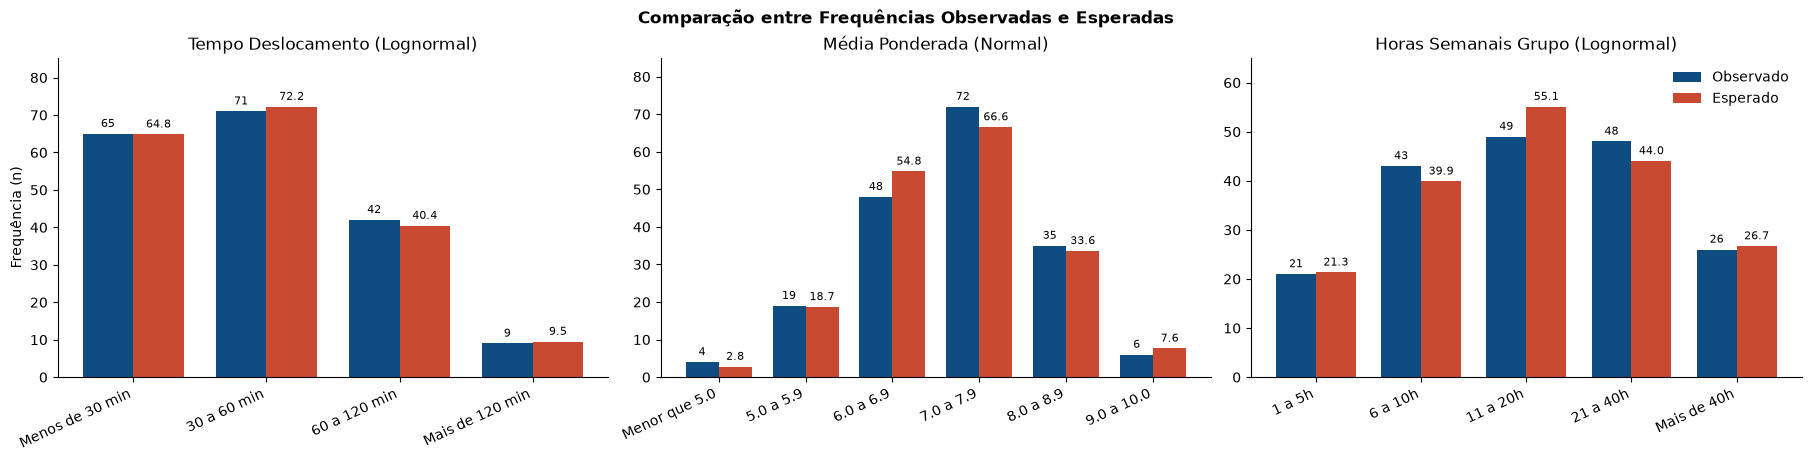

In [72]:
from src.plotting.plots_preprocessing import plot_observed_vs_expected

plots_data = [
    ("Tempo Deslocamento (Lognormal)", td_order, td_values, exp_td),
    ("Média Ponderada (Normal)", mp_order, mp_values, exp_mp),
    ("Horas Semanais Grupo (Lognormal)", hg_order, hg_values, exp_hg),
]

plot_observed_vs_expected(plots_data)
plt.savefig(OUTPUT_DIR / "figures" / "observed_vs_expected_values.png")
plt.show()

Há fortes evidências de falha em rejeitar a hipótese nula $H_0$, portanto consideraremos as aproximações como bons ajustes. A inspeção visual reforça essa percepção, portanto, adotaremos a aproximação. Para isso, criaremos uma coluna numérica onde substituiremos as faixas pelo valor esperado no intervalo (uma sofisticação da técnica do ponto médio, de certa forma).

$$\mathbb{E}[X | a_{j-1} < X < a_j] = \frac{\int_{a_j}^{a_{j-1}} x \cdot f(x | \hat{\theta}) dx}{F(a_j | \hat{\theta}) - F(a_{j-1} | \hat{\theta})}$$

Observe, no entanto, que testes não devem ser realizados com essas variáveis contínuas. Como foram aproximadas, elas não representam o comportamento real. Por outro lado, a distribuição pode ser útil para análise descritiva e predições (regressões).

In [73]:
from src.preprocessing import compute_bin_expected_values

td_dist = stats.lognorm(s=td_params[1], scale=np.exp(td_params[0]))
mp_dist = stats.norm(loc=mp_params[0], scale=mp_params[1])
hg_dist = stats.lognorm(s=hg_params[1], scale=np.exp(hg_params[0]))

td_exp_bins = compute_bin_expected_values(td_edges, td_dist)
mp_exp_bins = compute_bin_expected_values(mp_edges, mp_dist)
hg_exp_bins = compute_bin_expected_values(hg_edges, hg_dist)

mappings = {
    "tempo_deslocamento": dict(zip(td_order, compute_bin_expected_values(td_edges, td_dist))),
    "media_ponderada": dict(zip(mp_order, compute_bin_expected_values(mp_edges, mp_dist))),
    "horas_semanais_grupo": dict(zip(hg_order, compute_bin_expected_values(hg_edges, hg_dist))),
}

# Create new cols, indexed with "_num" suffix
for col, mapping in mappings.items():
    df_clean[f"{col}_num"] = df_clean[col].map(mapping).astype(float).round(2)

num_cols = [f"{key}_num" for key in mappings]
df_clean[num_cols].head()

,tempo_deslocamento_num,media_ponderada_num,horas_semanais_grupo_num
0,42.98,7.48,28.00
1,20.13,8.40,28.00
2,42.98,6.56,70.37
3,81.18,8.40,70.37
4,42.98,7.48,14.46


Podemos, por fim, finalizar o tratamento e pré-processamento. Usaremos o formato parquet para preservar os metadados de ordenamento das colunas categóricas.

In [74]:
df_clean.to_parquet(DATA_DIR / "clean_data.parquet", index=False)
print("Dataframe successfully saved.")

df_clean.head()

Dataframe successfully saved.


,curso,ano_ingresso,tipo_escola,tempo_deslocamento,faz_atividade_remunerada,renda_familiar,media_ponderada,area_pretendida,grupo_extensao,motivacao_ingresso,tempo_grupo,horas_semanais_grupo,objetivo_faculdade,momento_estagio,importancia_media,preparo_disciplinas,preparo_extensao,extra_esportes,extra_outro_grupo,extra_ca_gremio,grande_area_curso,categoria_extensao,anos_de_poli,delta_preparo,qtd_outras_atividades,tempo_deslocamento_num,media_ponderada_num,horas_semanais_grupo_num
0,Engenharia Civil,2026,Privada,30 a 60 min,Parcial / pontual,Acima de 20 salários mínimos,7.0 a 7.9,Empreendedorismo,Poli Júnior,Adquirir experiência prática em projetos reais,6 meses a 1 ano,21 a 40h,Grupo de extensão,No 3ºano,2,1,5,False,False,False,Civil & Ambiental,Consultoria & Negócios,1,4,0,42.98,7.48,28.00
1,Engenharia Elétrica,2026,Privada,Menos de 30 min,Não,Acima de 20 salários mínimos,8.0 a 8.9,Mercado Financeiro,Poli Júnior,Adquirir experiência prática em projetos reais,6 meses a 1 ano,21 a 40h,Grupo de extensão,No 4ºano,1,1,5,False,False,False,Elétrica & Computação,Consultoria & Negócios,1,4,0,20.13,8.40,28.00
2,Engenharia Elétrica,2025,Privada,30 a 60 min,Não,De 10 a 20 salários mínimos,6.0 a 6.9,Empreendedorismo,Poli Júnior,Interesse pela temática e objetivos do grupo,1 a 2 anos,Mais de 40h,Grupo de extensão,No 4ºano,3,3,4,False,False,False,Elétrica & Computação,Consultoria & Negócios,2,1,0,42.98,6.56,70.37
3,Engenharia Elétrica,2025,Privada,60 a 120 min,Não,Acima de 20 salários mínimos,8.0 a 8.9,Indefinido,Poli Júnior,"Desenvolvimento pessoal, comunicação e lideran...",1 a 2 anos,Mais de 40h,Grupo de extensão,No 4ºano,2,1,5,False,False,False,Elétrica & Computação,Consultoria & Negócios,2,4,0,81.18,8.40,70.37
4,Engenharia de Materiais/Metalúrgica/Nuclear,2025,Privada,30 a 60 min,Não,NaN,7.0 a 7.9,Consultoria,Poli Júnior,Interesse pela temática e objetivos do grupo,6 meses a 1 ano,11 a 20h,Grupo de extensão,No 4ºano,3,2,4,False,False,False,Outras Engenharias,Consultoria & Negócios,2,2,0,42.98,7.48,14.46


In [75]:
df_clean[sorted(df_clean.columns)].info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 187 entries, 0 to 186
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   ano_ingresso              187 non-null    int64   
 1   anos_de_poli              187 non-null    int64   
 2   area_pretendida           187 non-null    category
 3   categoria_extensao        187 non-null    str     
 4   curso                     187 non-null    category
 5   delta_preparo             187 non-null    int64   
 6   extra_ca_gremio           187 non-null    bool    
 7   extra_esportes            187 non-null    bool    
 8   extra_outro_grupo         187 non-null    bool    
 9   faz_atividade_remunerada  187 non-null    category
 10  grande_area_curso         187 non-null    category
 11  grupo_extensao            187 non-null    category
 12  horas_semanais_grupo      187 non-null    category
 13  horas_semanais_grupo_num  187 non-null    float64 
 14  impor